In [1]:
# source ~/load_modules_pitts_spack-26.1.sh
# module unload --no-auto py-typing-extensions py-pylint-gitlab -f
# module load py-pip
# OMP_NUM_THREADS=64 DISPLAY= PYTHONPATH=$PYTHONPATH:~/pitts_clean/examples/.python-packages/lib/python3.14/site-packages/:~/pitts_clean/build/src/ .python-packages/bin/jupyter notebook --no-browser --ip=0.0.0.0
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LightSource
import pitts_py
from IPython import display
import scipy.spatial
plt.rcParams['figure.figsize'] = [15, 10]
plt.rcParams['savefig.transparent'] = False
#plt.rcParams['agg.transparent'] = False

In [2]:
def saveVideo(name, data):
    file_name = "Interactive_DeepArc_examples_" + name + ".mp4"
    fourcc = cv2.VideoWriter_fourcc(*'vp09')
    n_frames = data.shape[0]
    width = data.shape[1]
    height = data.shape[2]
    out = cv2.VideoWriter(file_name, cv2.CAP_FFMPEG, fourcc, 30, (height, width), 1)
    normalized_data = data / np.max(data)
    normalized_data = np.maximum(0, normalized_data)
    cmap = plt.get_cmap('viridis')
    img_data = cmap(normalized_data, bytes=True)
    for i in range(n_frames):
        out.write(cv2.cvtColor(img_data[i,...], cv2.COLOR_RGBA2BGR))
    out.release()
    return file_name

In [3]:
def compareVideo(name, data_list):
    rows = 1 + (len(data_list)-1) // 5
    cols = min(5, len(data_list))
    t, x, y = data_list[0].shape
    all_data = np.zeros((t, x*rows, y*cols))
    for i, data in enumerate(data_list):
        row = i // 5
        col = i % 5
        all_data[:,row*x:(row+1)*x,col*y:(col+1)*y] = data
    return saveVideo(name, all_data)

In [4]:
def dict_to_tensortrain(tt_dict):
    Xtt = pitts_py.TensorTrain_float(tt_dict['dimensions'])
    Xtt.setTTranks(tt_dict['ranks'])
    for i in range(len(Xtt.dimensions())):
        Xtt.setSubTensor(i, tt_dict['cores'][i])
    return Xtt

In [5]:
x_on_disk_uin16 = np.load('/scratch/DeepArk_mirror/SANS_CM/stackedPixelData.npy', mmap_mode='r')[:18,...]
X = np.array(x_on_disk_uin16 / np.max(x_on_disk_uin16), dtype=np.float32)
np.save('DeepArc_data.npy', X)

In [5]:
%%time
# avoid uint16 to  float32 -> directly store float32...
X = np.load('DeepArc_data.npy')
# (patient, slice, time, x, y)
X.shape

CPU times: user 0 ns, sys: 2.38 s, total: 2.38 s
Wall time: 2.38 s


(18, 19, 300, 200, 200)

In [7]:
%%timeit
# avoid uint16 to  float32 -> directly store float32...
X = np.load('DeepArc_data.npy')
# (patient, slice, time, x, y)
X.shape

2.36 s ± 16.2 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [6]:
pitts_py.initialize()

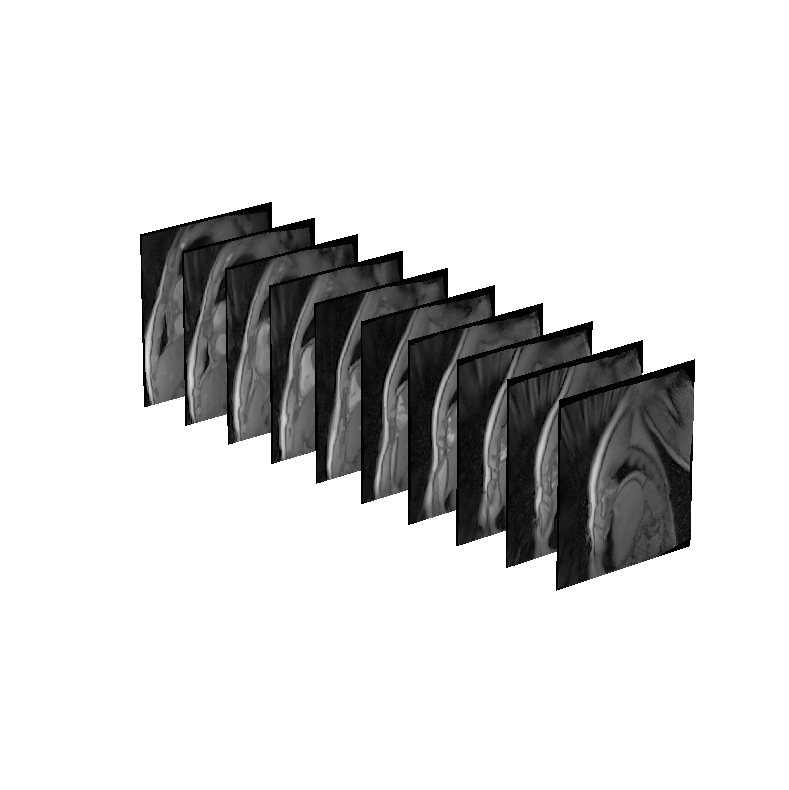

In [9]:
sliceFrames = X[0,:,0,:,:]
_X = np.arange(200)
_Y = np.arange(200)
_X, _Y = np.meshgrid(_X, _Y)
_Z = np.zeros((200,200))+10
cmap = plt.get_cmap('Greys_r')

#%matplotlib notebook
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.axis('off')
ls = LightSource(azdeg=-150)
#sliceFrames = np.rot90(sliceFrames, axes=(2, 1))
ax.plot_surface(_Y, _Z-0, -_X, facecolors=cmap(np.sqrt(sliceFrames[0,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z-1, -_X, facecolors=cmap(np.sqrt(sliceFrames[2,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z-2, -_X, facecolors=cmap(np.sqrt(sliceFrames[4,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z-3, -_X, facecolors=cmap(np.sqrt(sliceFrames[6,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z-4, -_X, facecolors=cmap(np.sqrt(sliceFrames[8,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z-5, -_X, facecolors=cmap(np.sqrt(sliceFrames[10,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z-6, -_X, facecolors=cmap(np.sqrt(sliceFrames[12,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z-7, -_X, facecolors=cmap(np.sqrt(sliceFrames[14,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z-8, -_X, facecolors=cmap(np.sqrt(sliceFrames[16,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z-9, -_X, facecolors=cmap(np.sqrt(sliceFrames[18,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.view_init(elev=20, azim=-130)
ax.set_box_aspect((4,15,4))
# plt.savefig('slices_gallery_.svg', dpi=4800, bbox_inches='tight', pad_inches=0, transparent=True)
# afterwards rescaling and saving in greyscale with GIMP

In [10]:
movie_ = X[2,0,:,:,:]
movie1_ = X[2,1,:,:,:]
movie2_ = X[2,2,:,:,:]
display.Video(compareVideo('sliceVideos_unsync3', (movie_[200:300,:,:], movie1_[200:300,:,:], movie2_[200:300,:,:])))

In [7]:
# scaling of X, so all images have norm 1 -> cosine similarity
X.shape

(18, 19, 300, 200, 200)

In [8]:
X_ = np.array(X.reshape((18,19,300,200*200), order='C', copy=False), dtype=np.float32)
X_.shape, X_.dtype

((18, 19, 300, 40000), dtype('float32'))

In [9]:
%%time
scaling = np.linalg.norm(X_, axis=3)

CPU times: user 3 s, sys: 1.16 s, total: 4.16 s
Wall time: 4.15 s


In [10]:
%%time
scaling = np.zeros(X_.shape[:-1], dtype=np.float32)
for i in range(scaling.shape[0]):
    for j in range(scaling.shape[1]):
        for k in range(scaling.shape[2]):
            scaling[i,j,k] = 1/np.linalg.norm(X_[i,j,k,:])

CPU times: user 7.33 s, sys: 53.9 ms, total: 7.38 s
Wall time: 751 ms


In [15]:
%%timeit
scaling = np.zeros(X_.shape[:-1], dtype=np.float32)
for i in range(scaling.shape[0]):
    for j in range(scaling.shape[1]):
        for k in range(scaling.shape[2]):
            scaling[i,j,k] = 1/np.linalg.norm(X_[i,j,k,:])

702 ms ± 2.48 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [11]:
%%time
X_normalized = X_ * scaling.reshape((18,19,300,1), order='C', copy=False)
X_normalized = X_normalized.reshape((18,19,300,200,200), order='C', copy=False)

CPU times: user 2.29 s, sys: 1.3 s, total: 3.59 s
Wall time: 1.83 s


In [17]:
%%timeit
X_normalized = X_ * scaling.reshape((18,19,300,1), order='C', copy=False)
X_normalized = X_normalized.reshape((18,19,300,200,200), order='C', copy=False)

1.81 s ± 5.87 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [12]:
# check correctness
np.linalg.norm(X_normalized[1,2,17,:,:])

np.float32(1.0)

In [13]:
%%time
# calculate similarity matrices
similarity = np.zeros((X_normalized.shape[0], X_normalized.shape[1]-1, X_normalized.shape[2], X_normalized.shape[2]), dtype=np.float32)
for i in range(similarity.shape[0]):
    for j in range(similarity.shape[1]):
        tmp1 = X_normalized[i,j,:,:,:].reshape((300,200*200), order='C', copy=False)
        tmp2 = X_normalized[i,j+1,:,:,:].reshape((300,200*200), order='C', copy=False)
        similarity[i,j,:,:] = tmp1 @ tmp2.T

CPU times: user 54.3 s, sys: 12.5 s, total: 1min 6s
Wall time: 1.05 s


In [20]:
%%timeit
# calculate similarity matrices
similarity = np.zeros((X_normalized.shape[0], X_normalized.shape[1]-1, X_normalized.shape[2], X_normalized.shape[2]), dtype=np.float32)
for i in range(similarity.shape[0]):
    for j in range(similarity.shape[1]):
        tmp1 = X_normalized[i,j,:,:,:].reshape((300,200*200), order='C', copy=False)
        tmp2 = X_normalized[i,j+1,:,:,:].reshape((300,200*200), order='C', copy=False)
        similarity[i,j,:,:] = tmp1 @ tmp2.T

728 ms ± 3.69 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [14]:
# cumulative sums (windowed sum), generated by Claude
def theta_diag(S, w=100):
    """theta[..., l, l'] = sum_{t=0}^{w-1} S[..., l+t, l'+t]"""
    n, L = S.shape[-1], S.shape[-1] - w + 1
    p = np.arange(n)[:, None]
    q = np.arange(2*n-1)[None, :] - (n-1) + p
    D = np.where((q >= 0) & (q < n), S[..., p, np.clip(q, 0, n-1)], 0)   # shear
    C = np.zeros(D.shape[:-2] + (n+1, 2*n-1), np.float64)
    np.cumsum(D, axis=-2, out=C[..., 1:, :])
    M = C[..., w:, :] - C[..., :-w, :]                                   # (..., L, 2n-1)
    l = np.arange(L)[:, None]
    return M[..., l, np.arange(L)[None, :] - l + (n-1)]                  # gather

In [15]:
%%time
summed_similarity = theta_diag(similarity)

CPU times: user 393 ms, sys: 130 ms, total: 523 ms
Wall time: 521 ms


In [23]:
%%timeit
summed_similarity = theta_diag(similarity)

519 ms ± 2.06 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [16]:
summed_similarity[5,8,23,42] - np.trace(similarity[5,8,23:23+100,42:42+100])

np.float64(9.357929229736328e-06)

In [17]:
# Viterbi algorithm for finding the max sum
def viterbi_all_patients(S_summed):
    l = np.zeros((19,19), dtype=np.int32)

    for i in range(18):
        v = np.zeros((19,201), dtype=np.float32)
        idx = np.zeros((18,201), dtype=np.int32)
        for j in range(18):
            M = v[j,:].reshape((201,1), order='C', copy=False) + S_summed[i,j,:,:]
            v[j+1,:] = np.max(M, axis=0)
            idx[j] = np.argmax(M, axis=0)
        l[i,18] = np.argmax(v[18,:])
        for j in reversed(range(18)):
            l[i,j] = idx[j][l[i,j+1]]

    return l

In [18]:
%%time
l = viterbi_all_patients(summed_similarity)

CPU times: user 80.8 ms, sys: 157 μs, total: 81 ms
Wall time: 79.3 ms


In [27]:
%%timeit
l = viterbi_all_patients(summed_similarity)

42.3 ms ± 22.4 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [28]:
i = 1
movies = [X[i,j,l[i,j]:l[i,j]+100,:,:] for j in range(19)]
display.Video(compareVideo('optimalSliceVideos1', movies))

In [19]:
def movie_from_tt(Xtt: pitts_py.TensorTrain_float, subT_idx: List[int]):
    subTensors = [Xtt.getSubTensor(i) for i in range(len(Xtt.dimensions()))]
    for i in subT_idx:
        subTensors[i] = subTensors[i][:,0:1,:]
    movie_tt = pitts_py.TensorTrain_float([subT.shape[1] for subT in subTensors])
    movie_tt.setTTranks([subT.shape[2] for subT in subTensors][:-1])
    for i, subT in enumerate(subTensors):
        movie_tt.setSubTensor(i, subT)
    print(movie_tt)
    movie = pitts_py.toDense(movie_tt)
    return movie.T

In [20]:
%%time
xtt_dict = np.load('Xtt_DeepArc_.npz', allow_pickle=True)
Xtt = dict_to_tensortrain(xtt_dict)
print(Xtt)

PITTS::TensorTrainfloat
        with dimensions = [100, 2, 5, 5, 2, 4, 3, 3, 2, 19, 2, 150]
             ranks      = [63, 96, 256, 717, 849, 604, 718, 581, 474, 40, 58]
CPU times: user 94.4 ms, sys: 299 ms, total: 394 ms
Wall time: 394 ms


In [31]:
movie = movie_from_tt(Xtt, [6,7,8,9]).reshape([300, 200, 200], order='C', copy=False)
display.Video(compareVideo('Xtt_DeepArc_example_movie', (movie, X[0,0,:,:,:])))

PITTS::TensorTrainfloat
        with dimensions = [100, 2, 5, 5, 2, 4, 1, 1, 1, 1, 2, 150]
             ranks      = [63, 96, 256, 717, 849, 604, 718, 581, 474, 40, 58]


In [21]:
for i in range(len(Xtt.dimensions())):
    subT = Xtt.getSubTensor(i)
    left = np.einsum('ijk,ijl->kl', subT, subT)
    right = np.einsum('ijk,ljk->il', subT, subT)
    print('Dim', i, 'left', np.linalg.norm(left - np.eye(*left.shape)) < 1.e-4, 'right', np.linalg.norm(right - np.eye(*right.shape)) < 1.e-4)

Dim 0 left True right False
Dim 1 left True right False
Dim 2 left True right False
Dim 3 left True right False
Dim 4 left True right False
Dim 5 left False right False
Dim 6 left False right True
Dim 7 left False right True
Dim 8 left False right True
Dim 9 left False right True
Dim 10 left False right True
Dim 11 left False right True


In [22]:
%%time
# left-normalize last sub-tensor of the frame x/y dimensions (others are already left-orthogonal due to two-sided TT-SVD)
subT5 = Xtt.getSubTensor(5)
M = subT5.reshape([subT5.shape[0]*subT5.shape[1], subT5.shape[2]], order='F')
R = np.linalg.qr(M, mode='r')
subT6 = Xtt.getSubTensor(6)
subT6 = (R @ subT6.reshape((subT6.shape[0], subT6.shape[1]*subT6.shape[2]), order='F')).reshape(subT6.shape, order='F')

CPU times: user 1.66 s, sys: 194 ms, total: 1.86 s
Wall time: 57.7 ms


In [34]:
%%timeit
# left-normalize last sub-tensor of the frame x/y dimensions (others are already left-orthogonal due to two-sided TT-SVD)
subT5 = Xtt.getSubTensor(5)
M = subT5.reshape([subT5.shape[0]*subT5.shape[1], subT5.shape[2]], order='F')
R = np.linalg.qr(M, mode='r')
subT6 = Xtt.getSubTensor(6)
subT6 = (R @ subT6.reshape((subT6.shape[0], subT6.shape[1]*subT6.shape[2]), order='F')).reshape(subT6.shape, order='F')

45.2 ms ± 215 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [23]:
%%time
dims = Xtt.dimensions()
r = subT6.shape[0]
I = np.eye(r, r, dtype=np.float32).reshape((1,r,r), order='C', copy=False)
dummy_subT = [I, subT6] + [Xtt.getSubTensor(i) for i in range(7, len(dims))]
dummy_tt = pitts_py.TensorTrain_float([r,] + dims[6:])
dummy_tt.setTTranks([subT.shape[2] for subT in dummy_subT[:-1]])
for i, subT in enumerate(dummy_subT):
    dummy_tt.setSubTensor(i, subT)
print(dummy_tt)
dummy = pitts_py.toDense(dummy_tt).reshape((r,18,19,300), order='F')

PITTS::TensorTrainfloat
        with dimensions = [604, 3, 3, 2, 19, 2, 150]
             ranks      = [604, 718, 581, 474, 40, 58]
CPU times: user 9.43 s, sys: 1.88 s, total: 11.3 s
Wall time: 225 ms


In [36]:
%%timeit
dims = Xtt.dimensions()
r = subT6.shape[0]
I = np.eye(r, r, dtype=np.float32).reshape((1,r,r), order='C', copy=False)
dummy_subT = [I, subT6] + [Xtt.getSubTensor(i) for i in range(7, len(dims))]
dummy_tt = pitts_py.TensorTrain_float([r,] + dims[6:])
dummy_tt.setTTranks([subT.shape[2] for subT in dummy_subT[:-1]])
for i, subT in enumerate(dummy_subT):
    dummy_tt.setSubTensor(i, subT)
print(dummy_tt)
dummy = pitts_py.toDense(dummy_tt).reshape((r,18,19,300), order='F')

PITTS::TensorTrainfloat
        with dimensions = [604, 3, 3, 2, 19, 2, 150]
             ranks      = [604, 718, 581, 474, 40, 58]
PITTS::TensorTrainfloat
        with dimensions = [604, 3, 3, 2, 19, 2, 150]
             ranks      = [604, 718, 581, 474, 40, 58]
PITTS::TensorTrainfloat
        with dimensions = [604, 3, 3, 2, 19, 2, 150]
             ranks      = [604, 718, 581, 474, 40, 58]
PITTS::TensorTrainfloat
        with dimensions = [604, 3, 3, 2, 19, 2, 150]
             ranks      = [604, 718, 581, 474, 40, 58]
PITTS::TensorTrainfloat
        with dimensions = [604, 3, 3, 2, 19, 2, 150]
             ranks      = [604, 718, 581, 474, 40, 58]
PITTS::TensorTrainfloat
        with dimensions = [604, 3, 3, 2, 19, 2, 150]
             ranks      = [604, 718, 581, 474, 40, 58]
PITTS::TensorTrainfloat
        with dimensions = [604, 3, 3, 2, 19, 2, 150]
             ranks      = [604, 718, 581, 474, 40, 58]
PITTS::TensorTrainfloat
        with dimensions = [604, 3, 3, 2, 19, 2, 150]

In [24]:
%%time
scaling_approx = np.zeros((18,19,300), dtype=np.float32)
for i in range(18):
    for j in range(19):
        for k in range(300):
            scaling_approx[i,j,k] = np.linalg.norm(dummy[:,i,j,k])

CPU times: user 246 ms, sys: 2.91 ms, total: 249 ms
Wall time: 247 ms


In [38]:
%%timeit
scaling_approx = np.zeros((18,19,300), dtype=np.float32)
for i in range(18):
    for j in range(19):
        for k in range(300):
            scaling_approx[i,j,k] = np.linalg.norm(dummy[:,i,j,k])

223 ms ± 327 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [25]:
%%time
dummy_normalized = dummy / scaling_approx.reshape((1,18,19,300), order='F', copy=False)

CPU times: user 37.1 ms, sys: 13 ms, total: 50.2 ms
Wall time: 48.9 ms


In [40]:
%%timeit
dummy_normalized = dummy / scaling_approx.reshape((1,18,19,300), order='F', copy=False)

50.3 ms ± 441 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [26]:
%%time
similarity_approx = np.zeros((18,18,300,300), dtype=np.float32)
for i in range(18):
    for j in range(18):
        similarity_approx[i,j,:,:] = dummy_normalized[:,i,j,:].T @ dummy_normalized[:,i,j+1,:]

CPU times: user 3.43 s, sys: 205 ms, total: 3.63 s
Wall time: 58.4 ms


In [42]:
%%timeit
similarity_approx = np.zeros((18,18,300,300), dtype=np.float32)
for i in range(18):
    for j in range(18):
        similarity_approx[i,j,:,:] = dummy_normalized[:,i,j,:].T @ dummy_normalized[:,i,j+1,:]

43.3 ms ± 213 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [27]:
np.max( (similarity_approx - similarity[:18,:,:,:]) / similarity[:18,:,:,:] )

np.float32(0.08356084)

In [28]:
%%time
summed_similarity_approx = theta_diag(similarity_approx)

CPU times: user 395 ms, sys: 140 ms, total: 535 ms
Wall time: 534 ms


In [45]:
%%timeit
summed_similarity_approx = theta_diag(similarity_approx)

523 ms ± 4.92 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [29]:
%%time
l_ = viterbi_all_patients(summed_similarity_approx)

CPU times: user 53.3 ms, sys: 1.04 ms, total: 54.4 ms
Wall time: 52.7 ms


In [47]:
%%timeit
l_ = viterbi_all_patients(summed_similarity_approx)

42.6 ms ± 48.4 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [30]:
# some random tests
rng = np.random.default_rng(0)
best_random = np.zeros(18)
for j in range(5000):
    l_dummy = [int(rng.integers(18)) for _ in range(19)]
    for i in range(18):
        best_random[i] = max(best_random[i], np.trace(summed_similarity[i,:,l_dummy[:-1],l_dummy[1:]]))
print('opt - best-of-5000-random \t opt - opt-approx')
for i in range(18):
    best = np.trace(summed_similarity[i,:,l[i,:-1],l[i,1:]])
    best_approx = np.trace(summed_similarity[i,:,l_[i,:-1],l_[i,1:]])
    print(best, '\t\t', best - best_random[i], '\t\t', best - best_approx)

opt - best-of-5000-random 	 opt - opt-approx
1607.9196819663048 		 11.496370553970337 		 0.3398858308792114
1640.714208304882 		 5.548109769821167 		 1.048690378665924
1668.3435117602348 		 9.593828201293945 		 0.7241486310958862
1681.9765546917915 		 15.327186048030853 		 0.610548734664917
1658.5479106903076 		 10.801741421222687 		 0.39308977127075195
1697.5320546030998 		 6.447092175483704 		 0.13578057289123535
1637.9409497380257 		 19.324778378009796 		 0.5114953517913818
1681.1425640583038 		 14.782357394695282 		 0.6383970379829407
1689.7431216835976 		 21.32543045282364 		 0.12801605463027954
1684.33814650774 		 8.315054774284363 		 0.4641910195350647
1664.4881058335304 		 11.4314506649971 		 0.1797083020210266
1637.3668631315231 		 6.3542521595954895 		 0.23084032535552979
1625.231169104576 		 7.0235870480537415 		 0.23921263217926025
1647.064633011818 		 8.70793467760086 		 0.4966365098953247
1673.4971258044243 		 5.0740578174591064 		 0.3084218502044678
1703.9508447051048 		

In [57]:
i = 0
movies = [X[i,j,l_[i,j]:l_[i,j]+100,:,:] for j in range(19)]
movies_ = [m - np.average(m[:,:,:], axis=0).reshape([1,200,200], order='C', copy=False) for m in movies]
display.Video(compareVideo('approxOptimalSliceVideos0_delta', movies_))

In [58]:
i = 0
movies = [X[i,j,l[i,j]:l[i,j]+100,:,:] for j in range(19)]
movies_ = [m - np.average(m[:,:,:], axis=0).reshape([1,200,200], order='C', copy=False) for m in movies]
display.Video(compareVideo('optimalSliceVideos0_delta', movies_))

In [31]:
%%time
xtt_dict = np.load('Xtt_DeepArc.npz', allow_pickle=True)
Xtt = dict_to_tensortrain(xtt_dict)
print(Xtt)

PITTS::TensorTrainfloat
        with dimensions = [100, 2, 5, 5, 2, 4, 3, 3, 2, 19, 2, 150]
             ranks      = [69, 109, 334, 1017, 1216, 1025, 1458, 932, 675, 51, 69]
CPU times: user 278 ms, sys: 398 ms, total: 676 ms
Wall time: 675 ms


In [32]:
movie = movie_from_tt(Xtt, [6,7,8,9]).reshape([300, 200, 200], order='C', copy=False)
display.Video(compareVideo('Xtt_DeepArc_example_movie', (movie, X[0,0,:,:,:])))

PITTS::TensorTrainfloat
        with dimensions = [100, 2, 5, 5, 2, 4, 1, 1, 1, 1, 2, 150]
             ranks      = [69, 109, 334, 1017, 1216, 1025, 1458, 932, 675, 51, 69]


In [33]:
for i in range(len(Xtt.dimensions())):
    subT = Xtt.getSubTensor(i)
    left = np.einsum('ijk,ijl->kl', subT, subT)
    right = np.einsum('ijk,ljk->il', subT, subT)
    print('Dim', i, 'left', np.linalg.norm(left - np.eye(*left.shape)) < 1.e-4, 'right', np.linalg.norm(right - np.eye(*right.shape)) < 1.e-4)

Dim 0 left True right False
Dim 1 left True right False
Dim 2 left True right False
Dim 3 left True right False
Dim 4 left True right False
Dim 5 left False right False
Dim 6 left False right True
Dim 7 left False right True
Dim 8 left False right True
Dim 9 left False right True
Dim 10 left False right True
Dim 11 left False right True


In [34]:
%%time
# left-normalize last sub-tensor of the frame x/y dimensions (others are already left-orthogonal due to two-sided TT-SVD)
subT5 = Xtt.getSubTensor(5)
M = subT5.reshape([subT5.shape[0]*subT5.shape[1], subT5.shape[2]], order='F')
R = np.linalg.qr(M, mode='r')
subT6 = Xtt.getSubTensor(6)
subT6 = (R @ subT6.reshape((subT6.shape[0], subT6.shape[1]*subT6.shape[2]), order='F')).reshape(subT6.shape, order='F')

CPU times: user 10 s, sys: 1.14 s, total: 11.2 s
Wall time: 175 ms


In [35]:
%%timeit
# left-normalize last sub-tensor of the frame x/y dimensions (others are already left-orthogonal due to two-sided TT-SVD)
subT5 = Xtt.getSubTensor(5)
M = subT5.reshape([subT5.shape[0]*subT5.shape[1], subT5.shape[2]], order='F')
R = np.linalg.qr(M, mode='r')
subT6 = Xtt.getSubTensor(6)
subT6 = (R @ subT6.reshape((subT6.shape[0], subT6.shape[1]*subT6.shape[2]), order='F')).reshape(subT6.shape, order='F')

158 ms ± 223 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [36]:
%%time
dims = Xtt.dimensions()
r = subT6.shape[0]
I = np.eye(r, r, dtype=np.float32).reshape((1,r,r), order='C', copy=False)
dummy_subT = [I, subT6] + [Xtt.getSubTensor(i) for i in range(7, len(dims))]
dummy_tt = pitts_py.TensorTrain_float([r,] + dims[6:])
dummy_tt.setTTranks([subT.shape[2] for subT in dummy_subT[:-1]])
for i, subT in enumerate(dummy_subT):
    dummy_tt.setSubTensor(i, subT)
print(dummy_tt)
dummy = pitts_py.toDense(dummy_tt).reshape((r,18,19,300), order='F')

PITTS::TensorTrainfloat
        with dimensions = [1025, 3, 3, 2, 19, 2, 150]
             ranks      = [1025, 1458, 932, 675, 51, 69]
CPU times: user 38.1 s, sys: 4.24 s, total: 42.3 s
Wall time: 661 ms


In [37]:
%%timeit
dims = Xtt.dimensions()
r = subT6.shape[0]
I = np.eye(r, r, dtype=np.float32).reshape((1,r,r), order='C', copy=False)
dummy_subT = [I, subT6] + [Xtt.getSubTensor(i) for i in range(7, len(dims))]
dummy_tt = pitts_py.TensorTrain_float([r,] + dims[6:])
dummy_tt.setTTranks([subT.shape[2] for subT in dummy_subT[:-1]])
for i, subT in enumerate(dummy_subT):
    dummy_tt.setSubTensor(i, subT)
print(dummy_tt)
dummy = pitts_py.toDense(dummy_tt).reshape((r,18,19,300), order='F')

PITTS::TensorTrainfloat
        with dimensions = [1025, 3, 3, 2, 19, 2, 150]
             ranks      = [1025, 1458, 932, 675, 51, 69]
PITTS::TensorTrainfloat
        with dimensions = [1025, 3, 3, 2, 19, 2, 150]
             ranks      = [1025, 1458, 932, 675, 51, 69]
PITTS::TensorTrainfloat
        with dimensions = [1025, 3, 3, 2, 19, 2, 150]
             ranks      = [1025, 1458, 932, 675, 51, 69]
PITTS::TensorTrainfloat
        with dimensions = [1025, 3, 3, 2, 19, 2, 150]
             ranks      = [1025, 1458, 932, 675, 51, 69]
PITTS::TensorTrainfloat
        with dimensions = [1025, 3, 3, 2, 19, 2, 150]
             ranks      = [1025, 1458, 932, 675, 51, 69]
PITTS::TensorTrainfloat
        with dimensions = [1025, 3, 3, 2, 19, 2, 150]
             ranks      = [1025, 1458, 932, 675, 51, 69]
PITTS::TensorTrainfloat
        with dimensions = [1025, 3, 3, 2, 19, 2, 150]
             ranks      = [1025, 1458, 932, 675, 51, 69]
PITTS::TensorTrainfloat
        with dimensions = [1025

In [38]:
%%time
scaling_approx = np.zeros((18,19,300), dtype=np.float32)
for i in range(18):
    for j in range(19):
        for k in range(300):
            scaling_approx[i,j,k] = np.linalg.norm(dummy[:,i,j,k])

CPU times: user 9.09 s, sys: 921 ms, total: 10 s
Wall time: 275 ms


In [39]:
%%timeit
scaling_approx = np.zeros((18,19,300), dtype=np.float32)
for i in range(18):
    for j in range(19):
        for k in range(300):
            scaling_approx[i,j,k] = np.linalg.norm(dummy[:,i,j,k])

230 ms ± 337 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [40]:
%%time
dummy_normalized = dummy / scaling_approx.reshape((1,18,19,300), order='F', copy=False)

CPU times: user 55.9 ms, sys: 40.1 ms, total: 96 ms
Wall time: 87.3 ms


In [41]:
%%timeit
dummy_normalized = dummy / scaling_approx.reshape((1,18,19,300), order='F', copy=False)

79 ms ± 1.03 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [42]:
%%time
similarity_approx = np.zeros((18,18,300,300), dtype=np.float32)
for i in range(18):
    for j in range(18):
        similarity_approx[i,j,:,:] = dummy_normalized[:,i,j,:].T @ dummy_normalized[:,i,j+1,:]

CPU times: user 4.89 s, sys: 259 ms, total: 5.15 s
Wall time: 85.4 ms


In [43]:
%%timeit
similarity_approx = np.zeros((18,18,300,300), dtype=np.float32)
for i in range(18):
    for j in range(18):
        similarity_approx[i,j,:,:] = dummy_normalized[:,i,j,:].T @ dummy_normalized[:,i,j+1,:]

55.1 ms ± 234 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [44]:
np.max( (similarity_approx - similarity[:18,:,:,:]) / similarity[:18,:,:,:] )

np.float32(0.05412683)

In [45]:
%%time
summed_similarity_approx = theta_diag(similarity_approx)

CPU times: user 9.6 s, sys: 1.11 s, total: 10.7 s
Wall time: 562 ms


In [46]:
%%timeit
summed_similarity_approx = theta_diag(similarity_approx)

520 ms ± 603 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [47]:
%%time
l__ = viterbi_all_patients(summed_similarity_approx)

CPU times: user 51.9 ms, sys: 3.1 ms, total: 55 ms
Wall time: 52 ms


In [48]:
%%timeit
l__ = viterbi_all_patients(summed_similarity_approx)

43.2 ms ± 1.82 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [49]:
# some random tests
rng = np.random.default_rng(0)
best_random = np.zeros(18)
for j in range(5000):
    l_dummy = [int(rng.integers(18)) for _ in range(19)]
    for i in range(18):
        best_random[i] = max(best_random[i], np.trace(summed_similarity[i,:,l_dummy[:-1],l_dummy[1:]]))
print('opt - best-of-5000-random \t opt - opt-approx')
for i in range(18):
    best = np.trace(summed_similarity[i,:,l[i,:-1],l[i,1:]])
    best_approx = np.trace(summed_similarity[i,:,l__[i,:-1],l__[i,1:]])
    print(best, '\t\t', best - best_random[i], '\t\t', best - best_approx)

opt - best-of-5000-random 	 opt - opt-approx
1607.9196819663048 		 11.496370553970337 		 0.1819537878036499
1640.714208304882 		 5.548109769821167 		 0.12255859375
1668.3435117602348 		 9.593828201293945 		 0.06650787591934204
1681.9765546917915 		 15.327186048030853 		 0.06387364864349365
1658.5479106903076 		 10.801741421222687 		 0.06196272373199463
1697.5320546030998 		 6.447092175483704 		 0.05010342597961426
1637.9409497380257 		 19.324778378009796 		 0.09206926822662354
1681.1425640583038 		 14.782357394695282 		 0.2982967495918274
1689.7431216835976 		 21.32543045282364 		 0.025207102298736572
1684.33814650774 		 8.315054774284363 		 0.14560425281524658
1664.4881058335304 		 11.4314506649971 		 0.09703481197357178
1637.3668631315231 		 6.3542521595954895 		 0.028181850910186768
1625.231169104576 		 7.0235870480537415 		 0.10632598400115967
1647.064633011818 		 8.70793467760086 		 0.035498082637786865
1673.4971258044243 		 5.0740578174591064 		 0.24677622318267822
1703.950844705

In [50]:
i = 0
movies = [X[i,j,l__[i,j]:l__[i,j]+100,:,:] for j in range(19)]
movies_ = [m - np.average(m[:,:,:], axis=0).reshape([1,200,200], order='C', copy=False) for m in movies]
display.Video(compareVideo('approxOptimalSliceVideos0_delta', movies_))